In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

In [2]:
df = pd.read_excel("rwi_per_kabupaten.xlsx")

In [3]:
kolom_kabupaten = "NAME_2"  # Ganti ke 'KABUPATEN' atau 'KAB_KOTA' jika nama kolom berbeda
kolom_provinsi = "NAME_1"
kolom_rwi = [c for c in df.columns if "rwi" in str(c).lower()][0]

=== STATISTIK DESKRIPTIF RWI NASIONAL ===
count    502.000000
mean       0.004170
std        0.462304
min       -0.672174
25%       -0.347048
50%       -0.181638
75%        0.279358
max        1.412167
Name: rata_rata_rwi, dtype: float64
=== 10 KABUPATEN/KOTA DENGAN RWI TERTINGGI ===
       NAME_1           NAME_2  rata_rata_rwi
  JakartaRaya     JakartaPusat       1.412167
    JawaBarat            Depok       1.366389
SumateraUtara          Sibolga       1.350500
    JawaBarat      KotaBandung       1.339250
  JakartaRaya   JakartaSelatan       1.318542
    JawaBarat       KotaBekasi       1.315763
   Yogyakarta   KotaYogyakarta       1.307500
  JakartaRaya     JakartaTimur       1.299813
       Banten TangerangSelatan       1.284593
         Bali         Denpasar       1.270136

=== 10 KABUPATEN/KOTA DENGAN RWI TERENDAH ===
         NAME_1            NAME_2  rata_rata_rwi
          Papua             Asmat      -0.672174
          Papua           Waropen      -0.655737
          Papua

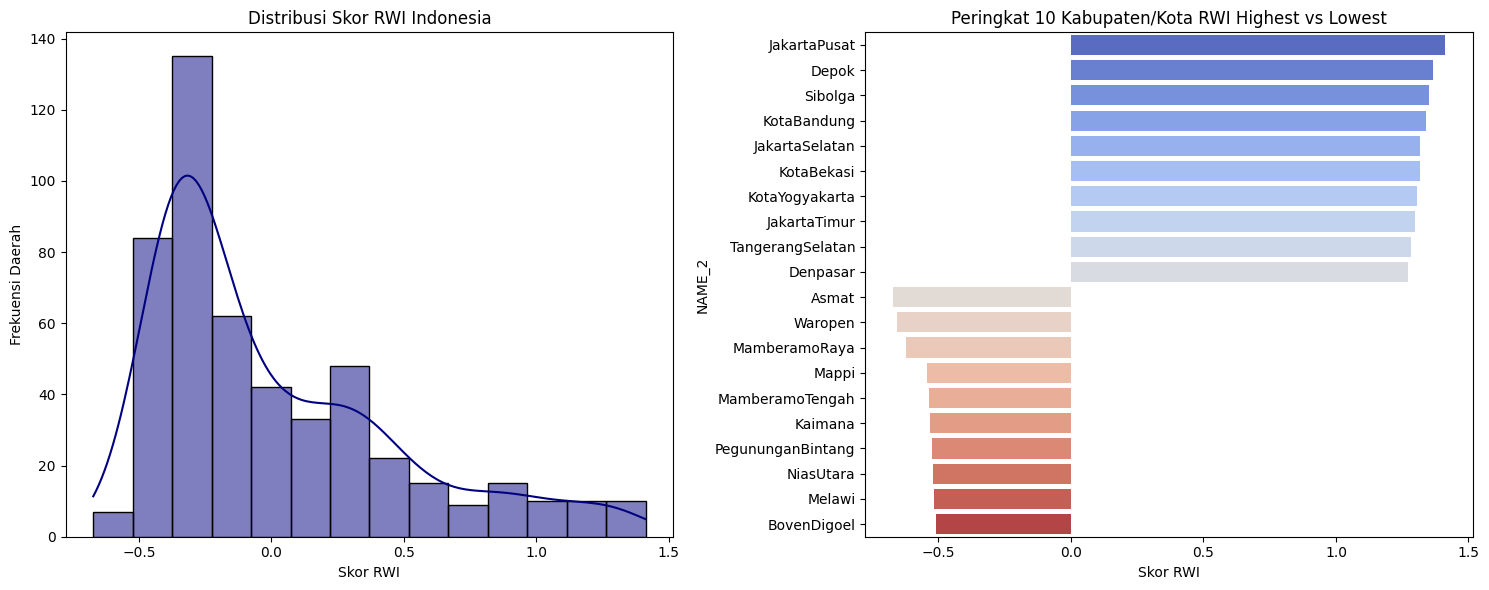

In [4]:
print("=== STATISTIK DESKRIPTIF RWI NASIONAL ===")
print(df[kolom_rwi].describe())

top_10 = df.sort_values(by=kolom_rwi, ascending=False).head(10)
bottom_10 = df.sort_values(by=kolom_rwi, ascending=True).head(10)

print("=== 10 KABUPATEN/KOTA DENGAN RWI TERTINGGI ===")
print(
    top_10[[kolom_provinsi, kolom_kabupaten, kolom_rwi]].to_string(index=False)
)

print("\n=== 10 KABUPATEN/KOTA DENGAN RWI TERENDAH ===")
print(
    bottom_10[[kolom_provinsi, kolom_kabupaten, kolom_rwi]].to_string(
        index=False
    )
)

# 4. Visualisasi Grafik Tanpa Warning & Tanpa Error Bar
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Histogram Distribusi
sns.histplot(df[kolom_rwi], kde=True, ax=axes[0], color="navy")
axes[0].set_title("Distribusi Skor RWI Indonesia")
axes[0].set_xlabel("Skor RWI")
axes[0].set_ylabel("Frekuensi Daerah")

# Barplot Highest vs Lowest
combined = pd.concat([top_10, bottom_10])
sns.barplot(
    data=combined,
    y=kolom_kabupaten,
    x=kolom_rwi,
    ax=axes[1],
    hue=kolom_kabupaten,
    palette="coolwarm",
    legend=False,
)
axes[1].set_title("Peringkat 10 Kabupaten/Kota RWI Highest vs Lowest")
axes[1].set_xlabel("Skor RWI")

plt.tight_layout()
plt.savefig("grafik_rwi_kabupaten.png", dpi=300)
plt.show()

In [5]:
def kelompokkan_pulau(prov):
  prov = str(prov).lower()
  if any(
      p in prov for p in ["jakarta", "jawa", "banten", "yogyakarta", "jogja"]
  ):
    return "Jawa"
  elif any(
      p in prov
      for p in [
          "sumatera",
          "sumatra",
          "aceh",
          "riau",
          "jambi",
          "lampung",
          "bengkulu",
          "bangka",
      ]
  ):
    return "Sumatera"
  elif "kalimantan" in prov:
    return "Kalimantan"
  elif "sulawesi" in prov:
    return "Sulawesi"
  elif "bali" in prov or "nusa" in prov:
    return "Bali & Nusa Tenggara"
  elif "papua" in prov or "maluku" in prov:
    return "Maluku & Papua"
  return "Lainnya"

In [6]:
df["Kawasan"] = df[kolom_provinsi].apply(kelompokkan_pulau)

ringkasan_kawasan = (
    df.groupby("Kawasan")[kolom_rwi]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .sort_values(by="mean", ascending=False)
)

print("=== RATA-RATA RWI PER KAWASAN ===")
print(ringkasan_kawasan)

=== RATA-RATA RWI PER KAWASAN ===
                      count      mean    median       std       min       max
Kawasan                                                                      
Jawa                    120  0.463209  0.327484  0.409964 -0.141492  1.412167
Bali & Nusa Tenggara     40  0.032665 -0.204314  0.472631 -0.466191  1.270136
Lainnya                   7 -0.036285 -0.298314  0.492455 -0.371417  0.863077
Sumatera                153 -0.100470 -0.249112  0.388545 -0.521921  1.350500
Sulawesi                 67 -0.140007 -0.282041  0.347279 -0.465226  1.139258
Kalimantan               55 -0.197907 -0.307917  0.333214 -0.518164  1.089000
Maluku & Papua           60 -0.315122 -0.365292  0.234551 -0.672174  0.530324


In [17]:
print(df['Kawasan'].value_counts())

Kawasan
Sumatera                153
Jawa                    120
Sulawesi                 67
Maluku & Papua           60
Kalimantan               55
Bali & Nusa Tenggara     40
Lainnya                   7
Name: count, dtype: int64


In [ ]:

print(df[df['Kawasan'] == 'Lainnya'][['NAME_2', 'NAME_1']])

            NAME_2     NAME_1
57         Boalemo  Gorontalo
58     BoneBolango  Gorontalo
59    DanauLimboto  Gorontalo
60       Gorontalo  Gorontalo
61  GorontaloUtara  Gorontalo
62   KotaGorontalo  Gorontalo
63        Pohuwato  Gorontalo


In [15]:
print(df[df['Kawasan'] == 'Lainnya'][['NAME_2', 'NAME_1']])

            NAME_2     NAME_1
57         Boalemo  Gorontalo
58     BoneBolango  Gorontalo
59    DanauLimboto  Gorontalo
60       Gorontalo  Gorontalo
61  GorontaloUtara  Gorontalo
62   KotaGorontalo  Gorontalo
63        Pohuwato  Gorontalo


In [18]:
def kelompokkan_pulau(prov):
  prov = str(prov).lower()
  if any(
      p in prov for p in ["jakarta", "jawa", "banten", "yogyakarta", "jogja"]
  ):
    return "Jawa"
  elif any(
      p in prov
      for p in [
          "sumatera",
          "sumatra",
          "aceh",
          "riau",
          "jambi",
          "lampung",
          "bengkulu",
          "bangka",
          "belitung",
      ]
  ):
    return "Sumatera"
  elif "kalimantan" in prov:
    return "Kalimantan"
  elif any(p in prov for p in ["sulawesi", "gorontalo"]):
    return "Sulawesi"
  elif "bali" in prov or "nusa" in prov:
    return "Bali & Nusa Tenggara"
  elif "papua" in prov or "maluku" in prov:
    return "Maluku & Papua"
  return "Lainnya"

In [19]:
df["Kawasan"] = df[kolom_provinsi].apply(kelompokkan_pulau)

In [20]:
print("=== DISTRIBUSI JUMLAH DAERAH PER KAWASAN ===")
print(df["Kawasan"].value_counts())
print("\nTotal Keseluruhan Sampel (N):", len(df))

=== DISTRIBUSI JUMLAH DAERAH PER KAWASAN ===
Kawasan
Sumatera                153
Jawa                    120
Sulawesi                 74
Maluku & Papua           60
Kalimantan               55
Bali & Nusa Tenggara     40
Name: count, dtype: int64

Total Keseluruhan Sampel (N): 502


In [21]:
ringkasan_kawasan = (
    df.groupby("Kawasan")[kolom_rwi]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .sort_values(by="mean", ascending=False)
)

print("\n=== RATA-RATA RWI PER KAWASAN (TABEL 4.4 BARU) ===")
print(ringkasan_kawasan)


=== RATA-RATA RWI PER KAWASAN (TABEL 4.4 BARU) ===
                      count      mean    median       std       min       max
Kawasan                                                                      
Jawa                    120  0.463209  0.327484  0.409964 -0.141492  1.412167
Bali & Nusa Tenggara     40  0.032665 -0.204314  0.472631 -0.466191  1.270136
Sumatera                153 -0.100470 -0.249112  0.388545 -0.521921  1.350500
Sulawesi                 74 -0.130195 -0.283984  0.360423 -0.465226  1.139258
Kalimantan               55 -0.197907 -0.307917  0.333214 -0.518164  1.089000
Maluku & Papua           60 -0.315122 -0.365292  0.234551 -0.672174  0.530324
